In [41]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import time
from sklearn.metrics import adjusted_rand_score

df = pd.read_csv("archive/CC GENERAL.csv")
df = df.drop("CUST_ID",axis="columns")
df

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6
8946,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.000000,6
8947,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6
8948,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6


In [42]:
df['MINIMUM_PAYMENTS'] = df['MINIMUM_PAYMENTS'].fillna(df['MINIMUM_PAYMENTS'].median())
df['CREDIT_LIMIT'] = df['CREDIT_LIMIT'].fillna(df['CREDIT_LIMIT'].median())
process_data = df.copy()

cc_columns = [
    'BALANCE', 
    'PURCHASES', 
    'ONEOFF_PURCHASES', 
    'INSTALLMENTS_PURCHASES', 
    'CASH_ADVANCE', 
    'CREDIT_LIMIT', 
    'PAYMENTS', 
    'MINIMUM_PAYMENTS', 
    'PURCHASES_TRX', 
    'CASH_ADVANCE_TRX'
]

process_data[cc_columns] = np.log1p(process_data[cc_columns])
sc = StandardScaler()
data = sc.fit_transform(process_data)
df['BALANCE'].max()

np.float64(19043.13856)

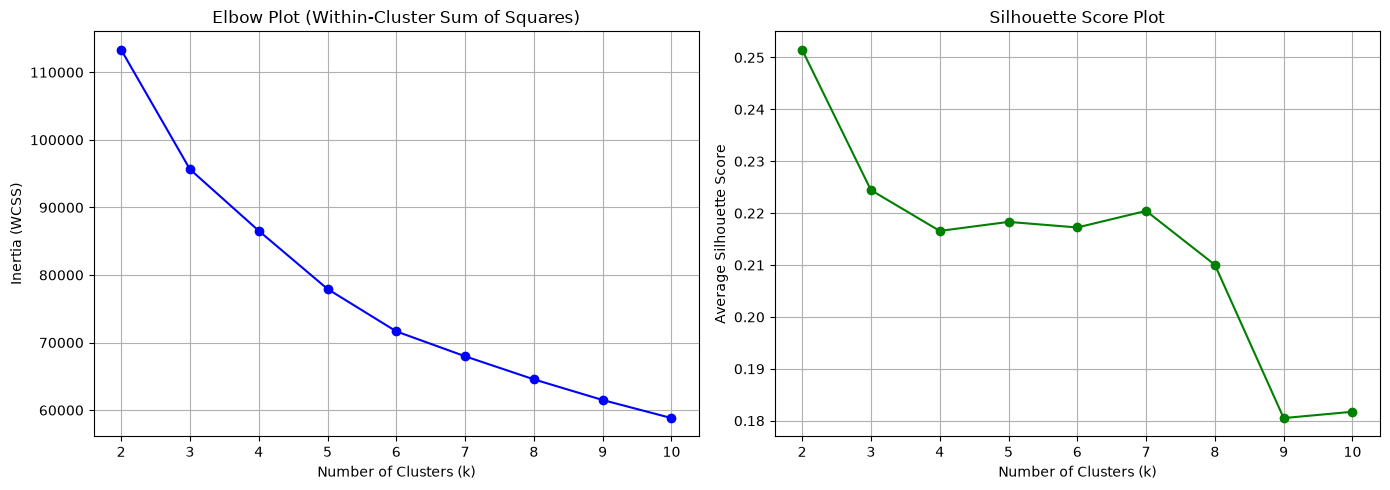

In [43]:
k_range = range(2, 11)
inertias = []
silhouettes = []

for k in k_range:
    kmeans = KMeans(
        n_clusters=k, 
        init="k-means++", 
        n_init=10, 
        random_state=42
    )
    # Fit and predict labels
    cluster_labels = kmeans.fit_predict(data)
    
    # Record WCSS (Inertia) and Silhouette score
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(data, cluster_labels))

# 4. Plotting the evaluation metrics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left Plot: Elbow Method (Inertia)
ax1.plot(k_range, inertias, marker='o', color='b', linestyle='-')
ax1.set_title('Elbow Plot (Within-Cluster Sum of Squares)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia (WCSS)')
ax1.set_xticks(k_range)
ax1.grid(True)

# Right Plot: Silhouette Score
ax2.plot(k_range, silhouettes, marker='o', color='g', linestyle='-')
ax2.set_title('Silhouette Score Plot')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Average Silhouette Score')
ax2.set_xticks(k_range)
ax2.grid(True)

plt.tight_layout()
plt.show()

Silhouette (higher better)              0.217
Davies-Bouldin (lower better)           1.466
Calinski-Harabasz (higher better)    2009.410
Runtime (s)                             0.175
dtype: float64 

        Customers     %
KMeans                 
0            2191  24.5
1            1458  16.3
2            1008  11.3
3            1667  18.6
4            1378  15.4
5            1248  13.9


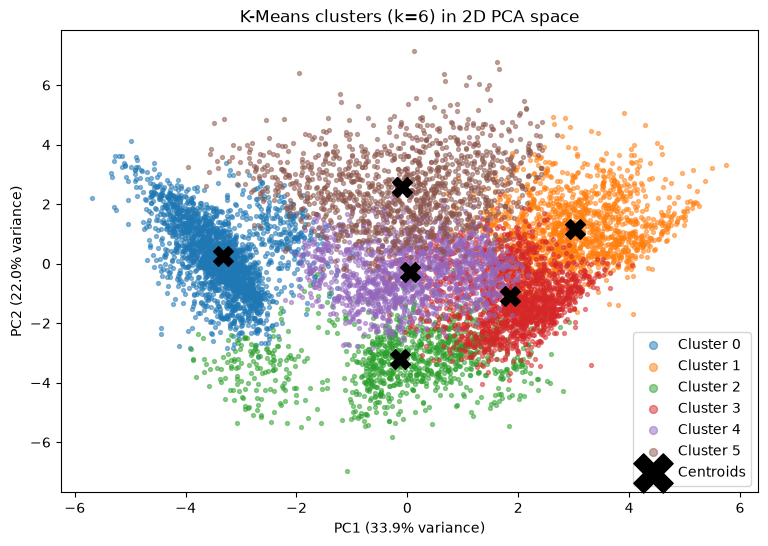

In [44]:
start = time.time()
kmeans = KMeans(n_clusters=6, init="k-means++", n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(data)
kmeans_time = time.time() - start

results = df.copy()
results["KMeans"] = kmeans_labels

kmeans_scores = pd.Series({
    "Silhouette (higher better)": silhouette_score(data, kmeans_labels),
    "Davies-Bouldin (lower better)": davies_bouldin_score(data, kmeans_labels),
    "Calinski-Harabasz (higher better)": calinski_harabasz_score(data, kmeans_labels),
    "Runtime (s)": kmeans_time,
}).round(3)
print(kmeans_scores, "\n")

sizes = results["KMeans"].value_counts().sort_index()
print(pd.DataFrame({"Customers": sizes, "%": (sizes / len(results) * 100).round(1)}))

pca_2d = PCA(n_components=2, random_state=42)
coords = pca_2d.fit_transform(data)
centers_2d = pca_2d.transform(kmeans.cluster_centers_)
var = pca_2d.explained_variance_ratio_ * 100

plt.figure(figsize=(9, 6))
for c in range(6):
    mask = kmeans_labels == c
    plt.scatter(coords[mask, 0], coords[mask, 1], s=8, alpha=0.5, label=f"Cluster {c}")
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker="X", s=200, label="Centroids")
plt.xlabel(f"PC1 ({var[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({var[1]:.1f}% variance)")
plt.title("K-Means clusters (k=6) in 2D PCA space")
plt.legend(markerscale=2)
plt.show()

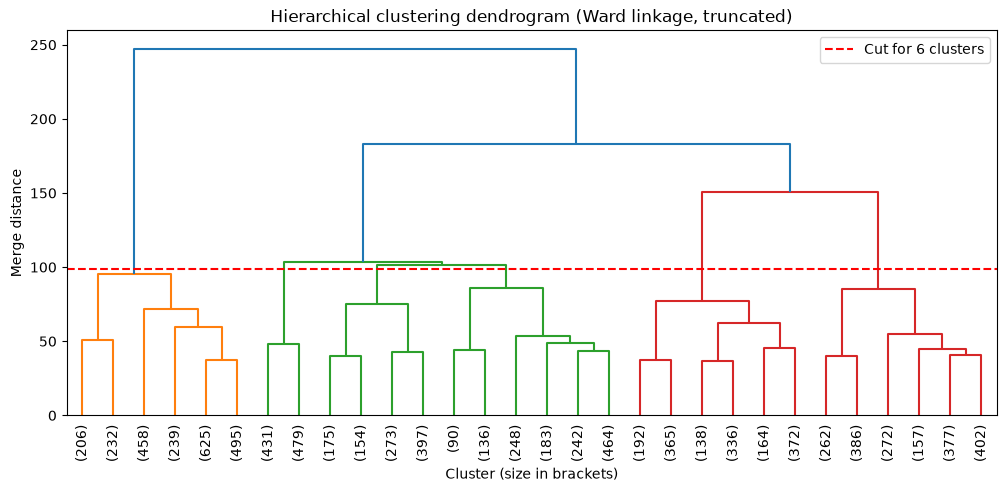

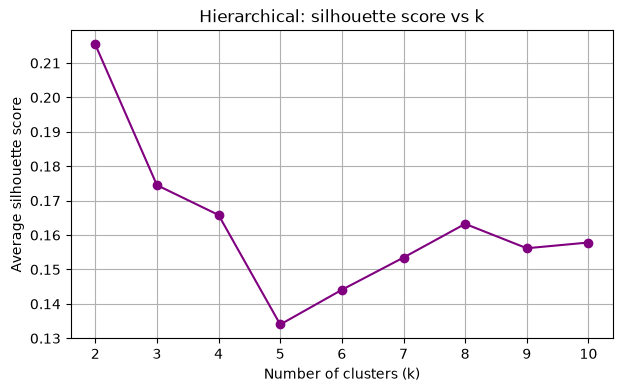

Silhouette (higher better)              0.144
Davies-Bouldin (lower better)           1.779
Calinski-Harabasz (higher better)    1489.835
Runtime (s)                             1.781
dtype: float64 

              Customers     %
Hierarchical                 
0                  2255  25.2
1                   910  10.2
2                   999  11.2
3                  1363  15.2
4                  1567  17.5
5                  1856  20.7


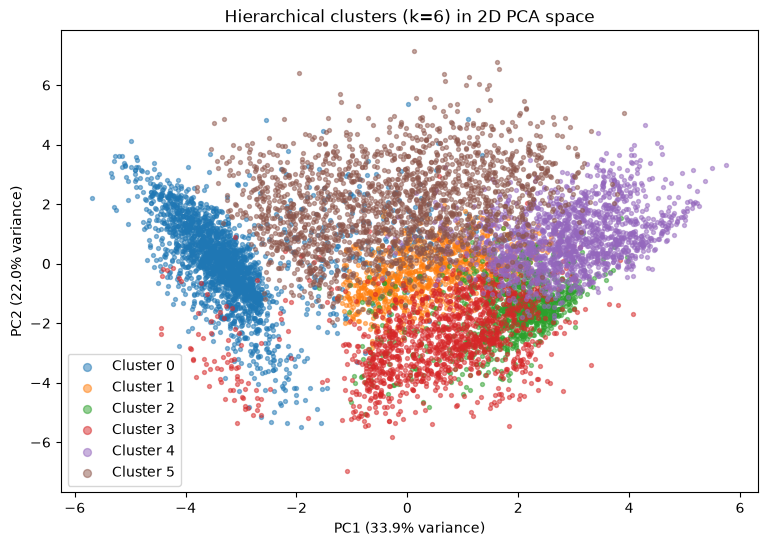

In [45]:
start = time.time()
Z = linkage(data, method="ward")
hc_time = time.time() - start

cut_height = (Z[-6, 2] + Z[-5, 2]) / 2
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, show_leaf_counts=True)
plt.axhline(cut_height, color="red", linestyle="--", label="Cut for 6 clusters")
plt.title("Hierarchical clustering dendrogram (Ward linkage, truncated)")
plt.xlabel("Cluster (size in brackets)")
plt.ylabel("Merge distance")
plt.legend()
plt.show()

hc_sil = {}
for k in range(2, 11):
    labels_k = fcluster(Z, t=k, criterion="maxclust") - 1
    hc_sil[k] = silhouette_score(data, labels_k)

plt.figure(figsize=(7, 4))
plt.plot(list(hc_sil.keys()), list(hc_sil.values()), marker="o", color="purple")
plt.title("Hierarchical: silhouette score vs k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average silhouette score")
plt.grid(True)
plt.show()

hc_labels = fcluster(Z, t=6, criterion="maxclust") - 1
results["Hierarchical"] = hc_labels

hc_scores = pd.Series({
    "Silhouette (higher better)": silhouette_score(data, hc_labels),
    "Davies-Bouldin (lower better)": davies_bouldin_score(data, hc_labels),
    "Calinski-Harabasz (higher better)": calinski_harabasz_score(data, hc_labels),
    "Runtime (s)": hc_time,
}).round(3)
print(hc_scores, "\n")

sizes = results["Hierarchical"].value_counts().sort_index()
print(pd.DataFrame({"Customers": sizes, "%": (sizes / len(results) * 100).round(1)}))

plt.figure(figsize=(9, 6))
for c in range(6):
    mask = hc_labels == c
    plt.scatter(coords[mask, 0], coords[mask, 1], s=8, alpha=0.5, label=f"Cluster {c}")
plt.xlabel(f"PC1 ({var[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({var[1]:.1f}% variance)")
plt.title("Hierarchical clusters (k=6) in 2D PCA space")
plt.legend(markerscale=2)
plt.show()

                                    K-Means  Hierarchical
Silhouette (higher better)            0.217         0.144
Davies-Bouldin (lower better)         1.466         1.779
Calinski-Harabasz (higher better)  2009.410      1489.835
Runtime (s)                           0.175         1.781 

K-Means sizes: [2191, 1458, 1008, 1667, 1378, 1248]
Hierarchical sizes: [2255, 910, 999, 1363, 1567, 1856] 

ARI between methods: 0.513
Hierarchical     0    1    2    3     4     5
KMeans                                       
0             1931    0    0   25     0   235
1                4   69   26   38  1176   145
2              110    4   76  804     0    14
3               19  103  849  314   296    86
4               60  734   48  176    83   277
5              131    0    0    6    12  1099


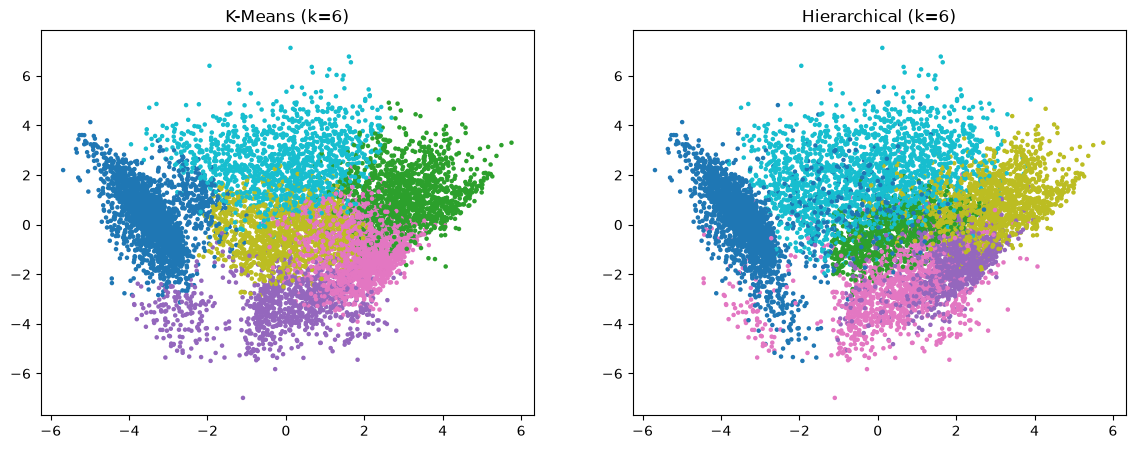

In [46]:
comparison = pd.DataFrame({"K-Means": kmeans_scores, "Hierarchical": hc_scores})
print(comparison, "\n")

print("K-Means sizes:", results["KMeans"].value_counts().sort_index().tolist())
print("Hierarchical sizes:", results["Hierarchical"].value_counts().sort_index().tolist(), "\n")

print("ARI between methods:", round(adjusted_rand_score(kmeans_labels, hc_labels), 3))
print(pd.crosstab(results["KMeans"], results["Hierarchical"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(coords[:, 0], coords[:, 1], c=kmeans_labels, cmap="tab10", s=5)
axes[0].set_title("K-Means (k=6)")
axes[1].scatter(coords[:, 0], coords[:, 1], c=hc_labels, cmap="tab10", s=5)
axes[1].set_title("Hierarchical (k=6)")
plt.show()